# Assignment 2: Linear Models and Support Vector Machines

.

In [346]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split

SEED = 42
np.set_printoptions(precision=4, suppress=True)

## Task 1: Load the datasets



In [347]:
diab = load_diabetes(scaled=False)
X_diab, y_diab = diab.data, diab.target


bc = load_breast_cancer()
X_bc, y_bc = bc.data, 1 - bc.target

dig = load_digits()
X_dig, y_dig = dig.data / 16, dig.target

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

print("Diabetes      X:", X_diab.shape, " y:", y_diab.shape)
print("Breast cancer X:", X_bc.shape, " y:", y_bc.shape)
print("Digits        X:", X_dig.shape, " y:", y_dig.shape)
print("Iris          X:", X_iris.shape, " y:", y_iris.shape)
print("Malignant count  :", y_bc.sum())

Diabetes      X: (442, 10)  y: (442,)
Breast cancer X: (569, 30)  y: (569,)
Digits        X: (1797, 64)  y: (1797,)
Iris          X: (150, 4)  y: (150,)
Malignant count  : 212


## PART1.A: Train / validation / test split

In [348]:

def split_data(X, y, stratify=True):

    if stratify:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42, stratify=y_tr)

    else:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42)

    return X_tr, X_va, X_te, y_tr, y_va, y_te


X_tr_diab, X_va_diab, X_te_diab, y_tr_diab, y_va_diab, y_te_diab = split_data(X_diab, y_diab, stratify=False)
X_tr_bc, X_va_bc, X_te_bc, y_tr_bc, y_va_bc, y_te_bc = split_data(X_bc, y_bc)
X_tr_dig, X_va_dig, X_te_dig, y_tr_dig, y_va_dig, y_te_dig = split_data(X_dig, y_dig)
X_tr_iris, X_va_iris, X_te_iris, y_tr_iris, y_va_iris, y_te_iris = split_data(X_iris, y_iris)


splits = [
    ("Diabetes", y_tr_diab, y_va_diab, y_te_diab),
    ("Breast cancer", y_tr_bc, y_va_bc, y_te_bc),
    ("Digits", y_tr_dig, y_va_dig, y_te_dig),
    ("Iris", y_tr_iris, y_va_iris, y_te_iris),
]

for name, y_tr, y_va, y_te in splits:
    print(f"{name:14s} train={len(y_tr):5d}  val={len(y_va):4d}  test={len(y_te):4d}  total={len(y_tr)+len(y_va)+len(y_te)}")
    if name != "Diabetes":
        print("   class counts train:", np.bincount(y_tr))
        print("   class counts val  :", np.bincount(y_va))
        print("   class counts test :", np.bincount(y_te))


Diabetes       train=  264  val=  89  test=  89  total=442
Breast cancer  train=  341  val= 114  test= 114  total=569
   class counts train: [214 127]
   class counts val  : [71 43]
   class counts test : [72 42]
Digits         train= 1077  val= 360  test= 360  total=1797
   class counts train: [106 109 107 109 109 109 109 107 104 108]
   class counts val  : [36 37 35 37 36 36 36 36 35 36]
   class counts test : [36 36 35 37 36 37 36 36 35 36]
Iris           train=   90  val=  30  test=  30  total=150
   class counts train: [30 30 30]
   class counts val  : [10 10 10]
   class counts test : [10 10 10]


## PARTA.2: Standardizer and add_bias

**Standardizer.** Each feature column is transformed as z = (x − μ) / σ. μ and σ are computed in `fit` from the training rows only, then `transform` applies those same values to any set (train, validation or test). If a column is constant (σ = 0), σ is replaced by 1 so we never divide by zero.

**add_bias.** Adds a column of ones at the left of X, giving X̃ = [1 | X]. The bias w₀ is then just another weight, and the score is simply ŷ = X̃w.


In [349]:
class Standardizer:
    """
    Standardizes features: z = (x - mu) / sigma.
    mu and sigma come from the TRAINING rows only (call fit on training data).
    """
    def fit(self, X):
        self.mu = X.mean(axis=0)
        self.sigma = X.std(axis=0)
        self.sigma[self.sigma == 0] = 1     # constant column: use sigma = 1 to avoid dividing by 0
        return self

    def transform(self, X):
        return (X - self.mu) / self.sigma

    
def add_bias(X):
    """
    Args:
      X (ndarray (m,n)) : features
    Returns:
      (ndarray (m,n+1)) : [1 | X], a column of ones added on the left
    """
    return np.hstack([np.ones((X.shape[0], 1)), X])

## Verify the Standardizer on diabetes dataset

The Standardizer is fitted on the **training** rows of Diabetes only, then applied unchanged to validation and test.

**Check:** the standardized training columns must have |mean| < 1e-9(close to 0) and std = 1, while the validation and test columns should generally not.

In [350]:
sc_diab = Standardizer().fit(X_tr_diab) 
Z_tr = sc_diab.transform(X_tr_diab)
Z_va = sc_diab.transform(X_va_diab)
Z_te = sc_diab.transform(X_te_diab)

print("train max |mean| :", np.abs(Z_tr.mean(axis=0)).max())
print("train std        :", Z_tr.std(axis=0))
print("val   mean       :", Z_va.mean(axis=0))
print("val   std        :", Z_va.std(axis=0))
print("test  mean       :", Z_te.mean(axis=0))
print("test  std        :", Z_te.std(axis=0))

assert np.abs(Z_tr.mean(axis=0)).max() < 1e-9
assert np.allclose(Z_tr.std(axis=0), 1)

train max |mean| : 2.2372676102294822e-15
train std        : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
val   mean       : [ 0.0231 -0.1458  0.043   0.1933  0.1431  0.0401  0.2174 -0.029   0.0104
 -0.2211]
val   std        : [0.9974 0.9859 1.0047 1.0004 0.9291 0.8845 1.1316 1.0666 1.1677 1.0717]
test  mean       : [-0.1488 -0.0559 -0.172  -0.0727  0.093   0.0919  0.1635 -0.0472 -0.1295
 -0.2546]
test  std        : [1.1232 0.9972 1.0255 0.908  0.9675 0.9697 1.0979 0.9999 1.0166 0.925 ]


We calculate μ (mean) and σ (standard deviation) using training rows only because the model should learn preprocessing from the training data, without seeing validation or test data.
If we calculate them using all rows, information from the test set leaks into the training process. This is called data leakage.We use training statistics only to ensure the test set remains unseen until the final evaluation, giving us a fair estimate of how well the model performs on new dat

## PARTA.3: Evaluation metrics

In [351]:
def mse(y, y_pred):
    """Mean squared error: mean((y - y_pred)^2)."""
    return np.mean((y - y_pred) ** 2)

def rmse(y, y_pred):
    """Root mean squared error, in the same units as y."""
    return np.sqrt(mse(y, y_pred))

def r2(y, y_pred):
    """R^2 = 1 - SS_res / SS_tot."""
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return 1 - ss_res / ss_tot

def accuracy(y, pred):
    """Fraction of predictions that equal the true labels."""
    return np.mean(y == pred)

def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y, pred), 1)
    return cm

def precision_recall_f1(cm):
    K = cm.shape[0]
    precision = []
    recall = []
    f1 = []

    for i in range(K):
        tp = cm[i, i]
        predicted = cm[:, i].sum()
        actual = cm[i, :].sum()

        p = tp / predicted if predicted > 0 else 0
        r = tp / actual if actual > 0 else 0
        f = 2 * p * r / (p + r) if p + r > 0 else 0

        precision.append(p)
        recall.append(r)
        f1.append(f)

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return (np.array(precision), np.array(recall), np.array(f1),
            macro_precision, macro_recall, macro_f1)

### Check against scikit-learn
Random labels (K = 4, N = 500) are used for the classification metrics and random continuous values for the regression metrics. Every result must agree with `sklearn.metrics` to within 1e-12.

In [352]:
from sklearn import metrics as skm

rng = np.random.default_rng(SEED)
K = 4
y_true = rng.integers(0, K, size=500)
y_pred = rng.integers(0, K, size=500)

cm = confusion_matrix(y_true, y_pred, K)
p, r, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(cm)


# Classification checks
assert np.array_equal(cm, skm.confusion_matrix(y_true, y_pred, labels=range(K)))
assert abs(accuracy(y_true, y_pred) - skm.accuracy_score(y_true, y_pred)) < 1e-12

# per class metrics
assert np.allclose(p, skm.precision_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(r, skm.recall_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(f1, skm.f1_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)

#per macro check
assert abs(macro_p - skm.precision_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_r - skm.recall_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_f1 - skm.f1_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12

# Regression checks
y_reg = rng.normal(size=500)
y_hat = y_reg + rng.normal(scale=0.5, size=500)

assert abs(mse(y_reg, y_hat) - skm.mean_squared_error(y_reg, y_hat)) < 1e-12
assert abs(rmse(y_reg, y_hat) - np.sqrt(skm.mean_squared_error(y_reg, y_hat))) < 1e-12
assert abs(r2(y_reg, y_hat) - skm.r2_score(y_reg, y_hat)) < 1e-12

print("All Task 3 checks passed")

All Task 3 checks passed


### Interpretation

All Task 3 evaluation metrics passed the verification checks against `sklearn.metrics` with a tolerance of \(10^{-12}\). This confirms that our implementations of the regression and classification metrics are correct. The confusion matrix also matches sklearn exactly.

## Task 4: Gradient checker

`grad_check(f, grad, w)` compares the analytic gradient with a numerical one computed by **central differences**:

(J(w + ε·eᵢ) − J(w − ε·eᵢ)) / (2ε)  for each parameter i.

- `f(w)` returns the scalar loss, and `grad(w)` returns the analytic gradient with the same shape as `w`.
- ε = 1e-5 by default (1e-6 for hinge losses).
- If `w` has more than 100 entries (softmax, multiclass SVM), 100 randomly chosen entries are checked.
- The function returns the relative error ‖g_analytic − g_numeric‖ / max(‖g_analytic‖, ‖g_numeric‖, 1e-12), which must be below 1e-6 (1e-5 for hinge losses).

**Check:** we test it on the linear-regression loss with the tiny dataset of Section 3.2. At w = 0 the gradient must be (−3.333, −7.667), and one gradient-descent step with η = 0.1 must give w = (0.333, 0.767).

In [353]:
def grad_check(f, grad, w, eps=1e-5, n_check=100):
    rng = np.random.default_rng(SEED)

    indices = np.arange(w.size)
    if w.size > n_check:
        indices = rng.choice(w.size, n_check, replace=False)

    numerical = np.zeros(len(indices))
    analytical = grad(w).ravel()[indices]

    for k, i in enumerate(indices):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        numerical[k] = (f(w_plus) - f(w_minus)) / (2 * eps)

    return np.linalg.norm(analytical - numerical) / max(
        np.linalg.norm(analytical),
        np.linalg.norm(numerical),
        1e-12
    )

In [354]:
X = add_bias(np.array([[1.0], [2.0], [3.0]]))
y = np.array([2.0, 3.0, 5.0])
N = len(y)

def J(w):
    return np.sum((np.dot(X, w) - y) ** 2) / (2 * N)

def grad(w):
    return np.dot(X.T, (np.dot(X, w) - y)) / N


# Worked example from Section 3.2
w0 = np.zeros(2)
print("gradient at w=0   :", grad(w0))
print("one GD step (0.1) :", w0 - 0.1 * grad(w0))


# Gradient check at a random point w ~ N(0, 0.1^2)
rng = np.random.default_rng(SEED)
w_rand = rng.normal(0, 0.1, size=2)

err = grad_check(J, grad, w_rand)

print("relative error    :", err)
assert err < 1e-6

gradient at w=0   : [-3.3333 -7.6667]
one GD step (0.1) : [0.3333 0.7667]
relative error    : 1.2891976616317198e-11


**Interpretation.** At w = 0 the analytic gradient is (−3.333, −7.667) and one step with η = 0.1 gives w = (0.333, 0.767), both matching the worked example of Section 3.2. The relative error between the analytic and numerical gradient is far below 1e-6, so both the gradient formula and the `grad_check` function are correct. We will call `grad_check` in every later Part before trusting any gradient.

## Part B: Linear regression

Dataset: **Diabetes** (442 patients, 10 features, target = disease progression in its original units).

In [355]:
import time
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor   # reference checks only (Section 8)

feature_names = list(diab.feature_names)

scaler = Standardizer().fit(X_tr_diab)
X_train = add_bias(scaler.transform(X_tr_diab))
X_val   = add_bias(scaler.transform(X_va_diab))
X_test  = add_bias(scaler.transform(X_te_diab))

y_train, y_val, y_test = y_tr_diab, y_va_diab, y_te_diab
X_train_raw = add_bias(X_tr_diab)       # raw features, used in Task 7

N_train = len(y_train)

## Task 5: Closed form (normal equations)

**Derivation.** Start from J(w) = (1/2N)(X̃w − y)ᵀ(X̃w − y).

1. Differentiate: ∇J = (1/N) X̃ᵀ(X̃w − y).
2. At the minimum the gradient is zero: X̃ᵀ(X̃w − y) = 0.
3. Expand: X̃ᵀX̃ w − X̃ᵀy = 0.
4. Rearrange: **X̃ᵀX̃ w = X̃ᵀy** (the normal equations).

J is convex (its Hessian X̃ᵀX̃/N is positive semi-definite), so the point where ∇J = 0 is the global minimum. We solve the linear system directly with `np.linalg.solve` instead of computing the inverse (X̃ᵀX̃)⁻¹, which is faster and numerically more stable.

**Check:** on the worked example of Section 3.2 we expect X̃ᵀX̃ = [[3,6],[6,14]], X̃ᵀy = [10, 23] and w = (1/3, 3/2).

In [356]:

def normal_equation(X, y):
    w = np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))
    return w

### Diabetes: weights and errors

The closed-form solution w* is computed on the standardized training data (with the bias column). The table lists the weights; RMSE is in the original units of the target, and R² is measured on the test set.

**Verification:** `LinearRegression` from scikit-learn is fitted on the same standardized training data; its intercept and coefficients must match our weights to within 1e-6.

In [357]:
w_star = normal_equation(X_train, y_train)

weights_table = pd.DataFrame({"feature": ["bias"] + feature_names, "w*": w_star})
print(weights_table.to_string(index=False))

print("\ntrain RMSE :", rmse(y_train, np.dot(X_train, w_star)))
print("val   RMSE :", rmse(y_val,   np.dot(X_val,   w_star)))
print("test  RMSE :", rmse(y_test,  np.dot(X_test,  w_star)))
print("test  R2   :", r2(y_test, np.dot(X_test, w_star)))
print("cond(X~'X~):", np.linalg.cond(np.dot(X_train.T, X_train)))


feature         w*
   bias 149.810606
    age   1.131837
    sex -11.359311
    bmi  25.076618
     bp  15.167338
     s1 -51.101359
     s2  27.480823
     s3  10.840294
     s4  15.032148
     s5  37.271588
     s6   3.817112

train RMSE : 54.6103635732402
val   RMSE : 51.193713978533914
test  RMSE : 54.15641293326044
test  R2   : 0.44642637640211247
cond(X~'X~): 505.7061226961072


## verification against sklearn

In [358]:
# Verify against scikit-learn
model = LinearRegression()
model.fit(X_train[:, 1:], y_train)

w_sklearn = np.r_[model.intercept_, model.coef_]

difference = np.max(np.abs(w_star - w_sklearn))

print("Maximum difference:", difference)
assert difference < 1e-6

Maximum difference: 9.734435479913373e-13


**Interpretation.** The weights calculated by our function are almost identical to those from `LinearRegression`, so our implementation is correct. The test RMSE is about 54, and the test R² is about 0.45, meaning the model explains around 45% of the variation in disease progression. The condition number is about 506, showing that the matrix is somewhat sensitive to numerical changes.

**s1, s2 and bmi.** bmi has a positive weight (+25), meaning that higher bmi is associated with higher predicted disease progression. s1 has a negative weight (−51), while s2 has a positive weight (+27). Since s1 and s2 are correlated, their weights may not show their individual effects accurately.

**Why is interpreting individual weights risky when features are correlated?** When two features are correlated, they contain similar information. The model may split their shared information between their weights in different ways. Therefore, we should be careful when interpreting each weight separately.

## Task 6: Batch gradient descent

In [359]:

def compute_cost(X, y, w):
    m = X.shape[0]
    f_w = np.dot(X, w)
    cost = np.sum((f_w - y) ** 2) / (2 * m)
    return cost


def compute_gradient(X, y, w):
    m = X.shape[0]
    f_w = np.dot(X, w)
    dj_dw = np.dot(X.T, f_w - y) / m
    return dj_dw


def gradient_descent(X, y, eta, num_epochs, w_star):
    m, n = X.shape
    w = np.zeros(n)

    J_history = np.zeros(num_epochs)
    dist_history = np.zeros(num_epochs)

    for epoch in range(num_epochs):
        dj_dw = compute_gradient(X, y, w)
        w = w - eta * dj_dw

        J_history[epoch] = compute_cost(X, y, w)
        dist_history[epoch] = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

        if not np.isfinite(J_history[epoch]) or J_history[epoch] > 1e30: #diverged
            break

    return w, J_history, dist_history


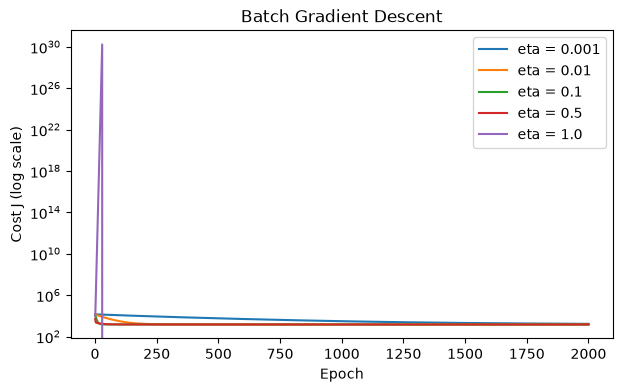

,eta,final J,final relative distance,first epoch below 1e-3
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,0.000000,0.000000,30


In [360]:

num_epochs = 2000
etas = [0.001, 0.01, 0.1, 0.5, 1.0]
results = []

plt.figure(figsize=(7, 4))

for eta in etas:
    w, J_history, dist_history = gradient_descent(
        X_train, y_train, eta, num_epochs, w_star
    )

    diverged = not np.isfinite(J_history[-1]) or J_history[-1] > J_history[0]

    reached = np.where(dist_history < 1e-3)[0]
    first_epoch = reached[0] + 1 if len(reached) > 0 else "not reached"

    plt.semilogy(range(1, num_epochs + 1), J_history, label=f"eta = {eta}")

    if diverged:
        final_J = "diverged"
        final_distance = "diverged"
    else:
        final_J = J_history[-1]
        final_distance = dist_history[-1]

    results.append({
        "eta": eta,
        "final J": final_J,
        "final relative distance": final_distance,
        "first epoch below 1e-3": first_epoch
    })

plt.xlabel("Epoch")
plt.ylabel("Cost J (log scale)")
plt.title("Batch Gradient Descent")
plt.legend()
plt.show()

pd.DataFrame(results)


### (b) The stability threshold 2/λmax

**Derivation.** Let e(t) = w(t) − w*. Since ∇J(w) = H(w − w*), one step of gradient descent gives

e(t+1) = e(t) − ηH e(t) = (I − ηH) e(t).

H = X̃ᵀX̃/N is symmetric, so H = QΛQᵀ with real eigenvalues λᵢ ≥ 0. In the eigenbasis each component evolves independently:

eᵢ(t+1) = (1 − ηλᵢ) eᵢ(t),  so  eᵢ(t) = (1 − ηλᵢ)ᵗ eᵢ(0).

A component goes to 0 if and only if |1 − ηλᵢ| < 1, that is 0 < η < 2/λᵢ. This must hold for **every** eigenvalue, and the tightest condition comes from the largest one, so

**η < 2/λmax.**

For η > 2/λmax the component along the top eigenvector is multiplied by a factor of magnitude greater than 1 at every step, so the error grows and gradient descent diverges.

In [361]:

# Calculate H
N = X_train.shape[0]
H = np.dot(X_train.T, X_train) / N

# Find the largest eigenvalue
lambda_max = np.max(np.linalg.eigvalsh(H))

print("Largest eigenvalue:", lambda_max)
print("Learning rate threshold:", 2 / lambda_max)


# Test two learning rates
for factor in [0.95, 1.05]:

    eta = factor * (2 / lambda_max)

    w, J_history, dist_history = gradient_descent(
        X_train, y_train, eta, num_epochs, w_star
    )

    if not np.isfinite(J_history[-1]) or J_history[-1] > 1e30:
        J_history[epoch:] = np.inf; dist_history[epoch:] = np.inf   
        print(f"eta = {eta:.4f}: Diverges")
    else:
        print(f"eta = {eta:.4f}: Converges")
        print("Final cost:", J_history[-1])
        print("Final distance:", dist_history[-1])


Largest eigenvalue: 3.9547550320503744
Learning rate threshold: 0.5057203249737277
eta = 0.4804: Converges
Final cost: 1491.145909733976
Final distance: 0.0002102307531542578
eta = 0.5310: Converges
Final cost: 0.0
Final distance: 0.0


## Task 7: Why scaling matters

Optimal J on raw features: 1491.14590480074


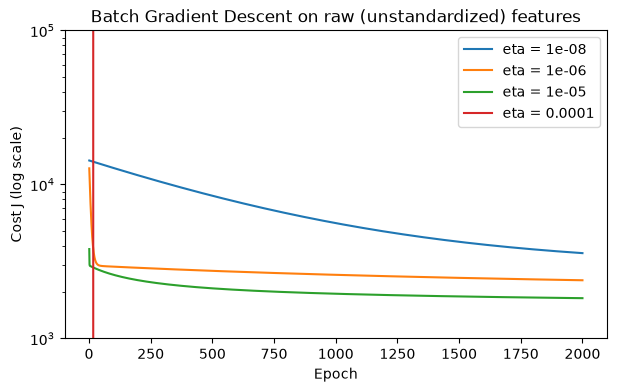

,eta,final J,final relative distance,first epoch below 1e-3
0,1.000000e-08,3583.532102,0.999999,not reached
1,1.000000e-06,2388.752582,0.999968,not reached
2,1.000000e-05,1827.53491,0.999846,not reached
3,1.000000e-04,diverged,diverged,not reached


In [362]:

w_star_raw = normal_equation(X_train_raw, y_train)
J_star = compute_cost(X_train_raw, y_train, w_star_raw)
print("Optimal J on raw features:", J_star)

num_epochs = 2000
etas_raw = [1e-8, 1e-6, 1e-5, 1e-4]
results_raw = []

plt.figure(figsize=(7, 4))

for eta in etas_raw:
    w, J_history, dist_history = gradient_descent(
        X_train_raw, y_train, eta, num_epochs, w_star_raw
    )

    diverged = (not np.all(np.isfinite(J_history))) or J_history.max() > 1e30

    plt.semilogy(range(1, num_epochs + 1), J_history, label=f"eta = {eta}")

    if diverged:
        final_J = "diverged"
        final_distance = "diverged"
        first_epoch = "not reached"
    else:
        final_J = J_history[-1]
        final_distance = dist_history[-1]
        reached = np.where(dist_history < 1e-3)[0]
        first_epoch = reached[0] + 1 if len(reached) > 0 else "not reached"

    results_raw.append({
        "eta": eta,
        "final J": final_J,
        "final relative distance": final_distance,
        "first epoch below 1e-3": first_epoch
    })

plt.ylim(1e3, 1e5)
plt.xlabel("Epoch")
plt.ylabel("Cost J (log scale)")
plt.title("Batch Gradient Descent on raw (unstandardized) features")
plt.legend()
plt.show()

pd.DataFrame(results_raw)


**Interpretation.** On raw features no run gets close to the optimal J = 1491.15: the best one (η = 1e-5) ends at 1827.5 and is still at a relative distance of 0.9998 from w*, while η = 1e-4 blows up. Compared with the standardized runs of Task 6, where η = 0.5 reached 1e-3 in 1524 epochs, the raw features make gradient descent hopeless within 2000 epochs.

In [363]:

rows = []
for name, X in [("raw", X_train_raw), ("standardized", X_train)]:
    H = np.dot(X.T, X) / N_train
    lambda_max = np.max(np.linalg.eigvalsh(H))
    rows.append({
        "features": name,
        "cond(X~'X~)": np.linalg.cond(np.dot(X.T, X)),
        "2/lambda_max": 2 / lambda_max
    })

pd.DataFrame(rows)


,features,cond(X~'X~),2/lambda_max
0,raw,5.577847e+07,0.000027
1,standardized,5.057061e+02,0.505720


**Condition number, learning rate and epochs.** Standardization reduces the condition number from about \(5.6 \times 10^7\) to 506 because it makes feature scales more similar. This also increases the maximum usable learning rate from about \(2.7 \times 10^{-5}\) to 0.51, allowing Gradient Descent to take larger steps. With raw features, the learning rate must be very small, so Gradient Descent needs many more epochs to approach the optimal solution. Therefore, standardization improves numerical stability and makes Gradient Descent converge much faster.

## Task 8: SGD and mini-batch gradient descent

In [364]:
def minibatch_gradient_descent(X, y, eta, num_epochs, batch_size, rng):

    m, n = X.shape
    w = np.zeros(n)
    n_batches = int(np.ceil(m / batch_size))

    J_epoch = np.zeros(num_epochs)
    J_update = np.zeros(num_epochs * n_batches)

    u = 0
    for epoch in range(num_epochs):
        idx = rng.permutation(m)     # reshuffle every epoch
        for b in range(n_batches):
            batch = idx[b * batch_size:(b + 1) * batch_size]
            dj_dw = compute_gradient(X[batch], y[batch], w)
            w = w - eta * dj_dw

            J_update[u] = compute_cost(X, y, w)# record updates after each batch
            u += 1

        J_epoch[epoch] = compute_cost(X, y, w)#record updates after each epoch

    return w, J_epoch, J_update


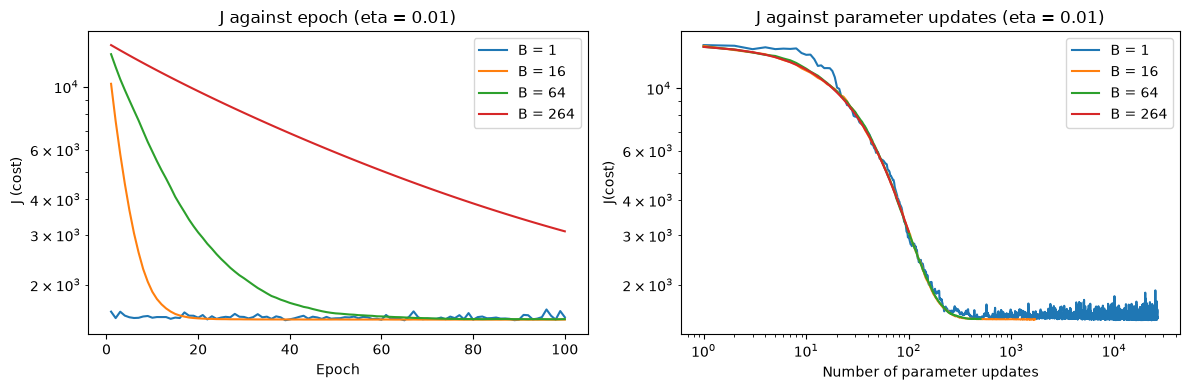

,B,updates,J after epoch 1,J after epoch 10,J after epoch 100,J after 500 updates
0,1,26400,1606.144970,1528.597292,1534.808385,1519.652701
1,16,1700,10236.368641,1887.933339,1505.665099,1509.10138
2,64,500,13021.996612,5904.012491,1511.375336,1511.375336
3,264,100,14021.698152,11648.152373,3085.440479,-


In [365]:
num_epochs = 100
eta = 0.01
batch_sizes = [1, 16, 64, N_train]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
results_B = []

for B in batch_sizes:
    rng = np.random.default_rng(SEED)
    w, J_epoch, J_update = minibatch_gradient_descent(
        X_train, y_train, eta, num_epochs, B, rng
    )

    ax[0].semilogy(range(1, num_epochs + 1), J_epoch, label=f"B = {B}")
    ax[1].loglog(range(1, len(J_update) + 1), J_update, label=f"B = {B}")

    results_B.append({
        "B": B,
        "updates": len(J_update),
        "J after epoch 1": J_epoch[0],
        "J after epoch 10": J_epoch[9],
        "J after epoch 100": J_epoch[-1],
        "J after 500 updates": J_update[499] if len(J_update) >= 500 else "-"
    })

ax[0].set_xlabel("Epoch")
ax[0].set_ylabel(" J (cost)")
ax[0].set_title("J against epoch (eta = 0.01)")
ax[0].legend()

ax[1].set_xlabel("Number of parameter updates")
ax[1].set_ylabel("J(cost)")
ax[1].set_title("J against parameter updates (eta = 0.01)")
ax[1].legend()

plt.tight_layout()
plt.show()

pd.DataFrame(results_B)

B = 16 performs best in our experiment, both after the same number of epochs and after the same number of updates. B = 1 is noisier because each update is based on only one training example,although it may reach a minimum but still so noisy.

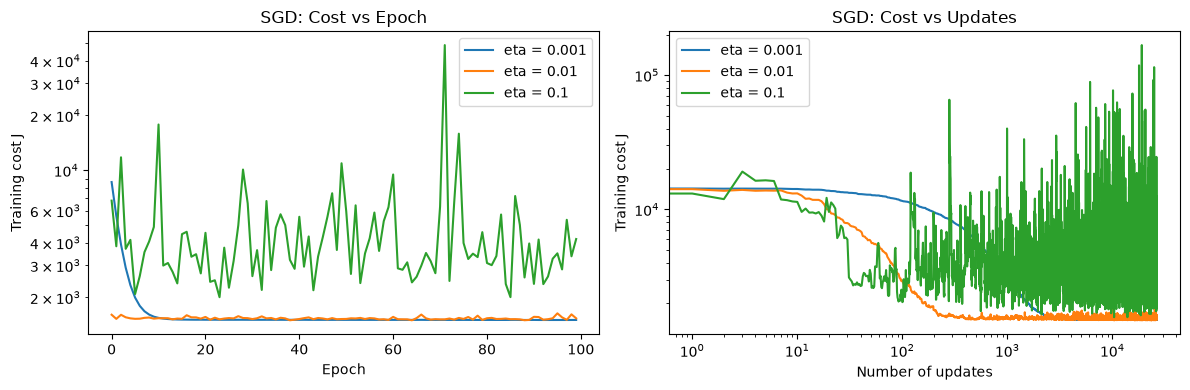

In [366]:

etas = [0.001, 0.01, 0.1]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for eta in etas:
    rng = np.random.default_rng(SEED)

    w, J_epoch, J_update = minibatch_gradient_descent(
        X_train, y_train, eta, num_epochs, 1, rng
    )

    ax[0].semilogy(J_epoch, label=f"eta = {eta}")
    ax[1].loglog(J_update, label=f"eta = {eta}")

ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Training cost J")
ax[0].set_title("SGD: Cost vs Epoch")
ax[0].legend()

ax[1].set_xlabel("Number of updates")
ax[1].set_ylabel("Training cost J")
ax[1].set_title("SGD: Cost vs Updates")
ax[1].legend()

plt.tight_layout()
plt.show()


Comment on how the noise level changes: SGD has high variance, so its cost curve is noisy. However, it can still approach the global minimum. With a constant learning rate, it may fluctuate around the minimum instead of reaching it exactly

# Part C: Logistic Regression
_AI assistance was used (Claude)_
## Task 11: Derivation and stable implementation

With $z = w^\top x$, $p = \sigma(z)$ and $\ell = -y\log p - (1-y)\log(1-p)$, the chain rule gives

$$\frac{\partial \ell}{\partial w} = \left(-\frac{y}{p} + \frac{1-y}{1-p}\right) p(1-p)\,x = (p-y)\,x$$

Averaging over $N$ samples and adding the regularizer gradient (the bias is not penalized):

$$\nabla J = \frac{1}{N}\tilde X^\top (p-y) + \lambda\,[0,\, w_{1:}]$$

**Stable loss.** Since $-\log(1-p) = \log(1+e^z)$ and $-\log p = \log(1+e^z) - z$:

$$\ell = \log(1+e^z) - y z$$

In [367]:
def sigmoid(z):
    e = np.exp(-np.abs(z))   
    return np.where(z >= 0, 1/(1+e), e/(1+e)) 
    # where: if z >= 0, return 1/(1+e), else return e/(1+e) on every element in np array

def term_loss(z, y):
    return np.logaddexp(0, z) - y*z

def mean_loss(w, x, y):                
    return np.mean(term_loss(np.dot(x, w), y))

def cost(w,x,y,lamda):
    z = np.dot(x, w)
    return np.mean(term_loss(z, y)) + 0.5*lamda*np.sum(w[1:]**2)
    # w[1:] we are not regularizing the bias term (w[0])

def gradient(w, x, y, lamda):
    g = np.dot(x.T, sigmoid(np.dot(x, w)) - y) / len(y)
    g[1:] += lamda * w[1:] # regularization except bias
    return g

def naive_sigmoid(z):
    return 1/(1+np.exp(-z))

def naive_loss(z, y):
    p = naive_sigmoid(z)
    return -y*np.log(p) - (1-y)*np.log(1-p)

with np.errstate(all="ignore"): # hide the overflow/divide errors
    for z in [800, -800]:
        for y in [0, 1]:
            print("z=", z, ", y=", y, "naive:", naive_loss(z, y), " stable:", term_loss(z, y))

sc_bc = Standardizer().fit(X_tr_bc)
Xb = add_bias(sc_bc.transform(X_tr_bc))
rng = np.random.default_rng(SEED)
w = rng.normal(0, 0.1, size=Xb.shape[1])

err = grad_check(lambda w: cost(w, Xb, y_tr_bc, 0.1),
                 lambda w: gradient(w, Xb, y_tr_bc, 0.1), w)
print(err); assert err < 1e-6

z= 800 , y= 0 naive: inf  stable: 800.0
z= 800 , y= 1 naive: nan  stable: 0.0
z= -800 , y= 0 naive: nan  stable: 0.0
z= -800 , y= 1 naive: inf  stable: 800.0
1.7775135713047355e-11


**Interpretation.** For $z=\pm 800$ the naive formula fails: $\sigma(800)$ rounds to exactly 1, so $\log(1-p)=\log 0$ gives `nan` or `inf`. The stable form $\log(1+e^z) - yz$ returns the correct values (0 when the prediction is confidently right, 800 when confidently wrong). The gradient check gives a relative error far below $10^{-6}$ with $\lambda=0.1$, so the derived gradient and its code are correct.

## Task 12: Training and regularization

We train logistic regression with batch gradient descent (η = 0.5, 3000 epochs, w initialized to 0) for different values of the regularization strength λ ∈ {0, 1e-3, 1e-2, 1e-1, 1}.

- For each λ we report train accuracy, validation accuracy, validation loss (data term only) and ‖w₁:‖.
- We choose λ* by the lowest **validation loss**, then report the **test accuracy once**, only for λ*.
- For λ* we plot the train and validation loss and accuracy against the epoch.
- Separately, we try learning rates η ∈ {0.01, 0.1, 1, 5, 20} for 1000 epochs at λ = 0.01 and compare the final training loss to see which ones are too small or too large.


,lambda,train accuracy,validation accuracy,validation loss,||w1:||
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.073203,5.099928
2,0.010,0.985337,0.973684,0.082964,2.325749
3,0.100,0.973607,0.973684,0.141553,1.105547
4,1.000,0.938416,0.956140,0.292213,0.441485


lambda* = 0.001
test accuracy: 0.9736842105263158


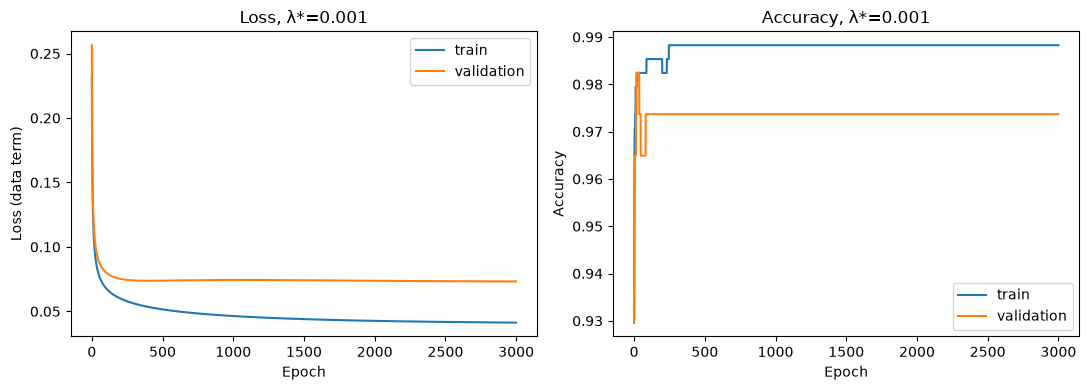

,eta,final train loss
0,0.01,0.105222
1,0.10,0.072909
2,1.00,0.071066
3,5.00,0.071066
4,20.00,0.649280


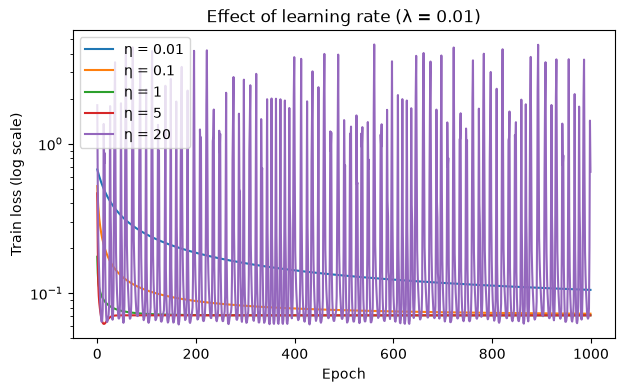

In [368]:
def predict(w, x, threshold=0.5):
    return (sigmoid(np.dot(x, w)) >= threshold).astype(int)

def train_gd(Xtr, ytr, lamda, eta, epochs, Xva=None, yva=None):
    w = np.zeros(Xtr.shape[1]) # initialize w = 0 
    h = {"train_loss": [], "validation_loss": [], "train_accuracy": [], "validation_accuracy": [], "w_norm": []}
    for i in range(epochs):
        w = w - eta * gradient(w, Xtr, ytr, lamda)
        h["train_loss"].append(mean_loss(w, Xtr, ytr))
        h["train_accuracy"].append(accuracy(ytr, predict(w, Xtr)))
        h["w_norm"].append(np.linalg.norm(w[1:]))
        if Xva is not None:
            h["validation_loss"].append(mean_loss(w, Xva, yva))
            h["validation_accuracy"].append(accuracy(yva, predict(w, Xva)))
    return w, h

Xtr = add_bias(sc_bc.transform(X_tr_bc))
Xva = add_bias(sc_bc.transform(X_va_bc))
Xte = add_bias(sc_bc.transform(X_te_bc))

lamdas = [0, 1e-3, 1e-2, 1e-1, 1]
rows, runs = [], {}
for lamda in lamdas:
    w, h = train_gd(Xtr, y_tr_bc, lamda, 0.5, 3000, Xva, y_va_bc)
    runs[lamda] = (w, h)
    rows.append({"lambda": lamda,
                 "train accuracy": h["train_accuracy"][-1],
                 "validation accuracy": h["validation_accuracy"][-1],
                 "validation loss": h["validation_loss"][-1],
                 "||w1:||": np.linalg.norm(w[1:])})
table = pd.DataFrame(rows); display(table)

# find the best lambda based on validation loss
best_lamda = table.loc[table["validation loss"].idxmin(), "lambda"]
w_best, h_best = runs[best_lamda]
print("lambda* =", best_lamda)
print("test accuracy:", accuracy(y_te_bc, predict(w_best, Xte)))

# plot the loss and accuracy curves for the best lambda
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h_best["train_loss"], label="train"); ax[0].plot(h_best["validation_loss"], label="validation")
ax[0].set(xlabel="Epoch", ylabel="Loss (data term)", title=f"Loss, λ*={best_lamda}"); ax[0].legend()
ax[1].plot(h_best["train_accuracy"], label="train"); ax[1].plot(h_best["validation_accuracy"], label="validation")
ax[1].set(xlabel="Epoch", ylabel="Accuracy", title=f"Accuracy, λ*={best_lamda}"); ax[1].legend()
plt.tight_layout(); plt.show()

# proving η = 20 fails to converge
rows, curves = [], {}
for eta in [0.01, 0.1, 1, 5, 20]:
    w, h = train_gd(Xtr, y_tr_bc, 0.01, eta, 1000)
    curves[eta] = h["train_loss"]
    rows.append({"eta": eta, "final train loss": h["train_loss"][-1]})
display(pd.DataFrame(rows))

plt.figure(figsize=(7, 4))
for eta, c in curves.items():
    plt.semilogy(c, label=f"η = {eta}")
plt.xlabel("Epoch"); plt.ylabel("Train loss (log scale)")
plt.title("Effect of learning rate (λ = 0.01)"); plt.legend(); plt.show()

**Interpretation (λ sweep).** Increasing λ shrinks the weights: ‖w₁:‖ falls from 8.13 (λ = 0) to 5.10, 2.33, 1.11 and 0.44 (λ = 1). The validation loss is lowest at λ = 0.001 (0.0732, so λ* = 0.001) and rises on both sides: 0.0842 with no regularization and 0.2922 at λ = 1, about 4× the best, so λ = 1 is clearly over-regularized and the model underfits (train accuracy drops to 0.938). The test accuracy at λ* is 0.974, reported once. Note that λ = 0 only reaches train accuracy 0.994 after 3000 epochs because the data is separable and the weights are still growing (Task 13). In the curves for λ*, the training loss keeps falling to about 0.04 while the validation loss flattens at about 0.073 after roughly 300 epochs, a small generalization gap, and both accuracies stay stable after that.

**Interpretation (learning rate).** η = 0.01 is too small: after 1000 epochs the loss is still high (0.105) and decreasing, so it is under-trained. η = 0.1 is close (0.0729), and η = 1 and η = 5 both reach the minimum loss of 0.0711, so they have converged. η = 20 is too large: each step overshoots the minimum, the loss oscillates between about 0.06 and 4 and never settles (final value 0.649), as the purple curve shows. Our stable loss keeps this from producing `nan`.

## Task 13: Separability

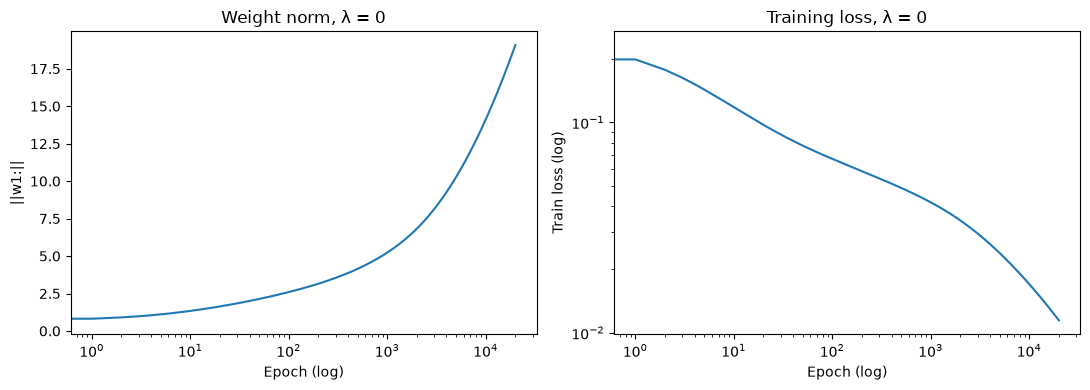

final train accuracy: 1.0
final train loss: 0.011458238949846758  ||w||: 19.07910409109684


In [369]:
w, h = train_gd(Xtr, y_tr_bc, 0, 0.5, 20000)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogx(h["w_norm"]); ax[0].set(xlabel="Epoch (log)", ylabel="||w1:||", title="Weight norm, λ = 0")
ax[1].loglog(h["train_loss"]); ax[1].set(xlabel="Epoch (log)", ylabel="Train loss (log)", title="Training loss, λ = 0")
plt.tight_layout(); plt.show()

print("final train accuracy:", h["train_accuracy"][-1])
print("final train loss:", h["train_loss"][-1], " ||w||:", h["w_norm"][-1])

**Interpretation.** With λ = 0, ‖w₁:‖ keeps growing (to 19.1 after 20,000 epochs) while the training loss keeps shrinking (to 0.0115) and training accuracy reaches 1.0. This indicates that the training set is linearly separable: some w classifies every point correctly.

For separable data, replacing a separating w by c·w with c > 1 makes every margin larger, so every sample's loss strictly decreases. The loss can therefore be pushed toward 0 but never reaches it, so the infimum is not attained by any finite w, no minimizer exists, and the weights diverge.

With L2 the cost is J(w) ≥ (λ/2)‖w₁:‖², which tends to infinity as ‖w₁:‖ → ∞, and the penalty is strictly convex in w₁:. So J has a finite, unique minimizer. This matches Task 12, where every λ > 0 gave a finite ‖w₁:‖ (for example 5.10 at λ = 0.001).

## Task 14: Off-the-shelf comparison

We compare our from-scratch logistic regression with scikit-learn's `LogisticRegression`. The two use different regularization parameters, related by $C = \frac{1}{\lambda N}$ (for $\lambda = 0$ we use `penalty=None`). Since our matrix already contains a bias column, scikit-learn is given the features without it, because it adds its own intercept.

- **Fit for each λ of Task 12** and report train and validation accuracy.
- **Verify at λ = 0.01** (`tol=1e-12`, `max_iter=100000`): our weights, including the bias, must match scikit-learn's with relative error below $10^{-4}$, and the test predictions must agree.
- **Sweep C** over {0.001, ..., 1000} and report train, validation and test accuracy.
- **Compare the solvers** lbfgs, liblinear and saga at C = 1: iterations, time, and difference in coefficients. liblinear also penalizes the intercept, which changes its solution slightly.

In [370]:
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.linear_model import LogisticRegression
import time

N = len(y_tr_bc)

# get the weights from scikit-learn
def fit_sk(lamda, **kw):
    if lamda == 0:
        clf = LogisticRegression(penalty=None, **kw) # clf.intercept_ has bias, clf.coef_ has the rest of the weights
        # **kw passes any additional keyword arguments to the LogisticRegression constructor 
    else:
        clf = LogisticRegression(C=1/(lamda*N), **kw) # uses C = 1 / (λ · N) instead of λ
    clf.fit(Xtr[:, 1:], y_tr_bc) #train while removing the bias term from the features, since sklearn adds it automatically
    sk_weights = np.r_[clf.intercept_, clf.coef_.ravel()] # glue the bias term and the rest of the weights into a single vector
    return clf, sk_weights

# train for each lamda of task 12
rows = []
for lamda in [0, 1e-3, 1e-2, 1e-1, 1]:
    clf, sk_weights = fit_sk(lamda, tol=1e-12, max_iter=100000) #stop when the weights change by less than 1e-12 or after 100000 iterations
    rows.append({"lambda": lamda,
                 "train accuracy": clf.score(Xtr[:, 1:], y_tr_bc),
                 "validation accuracy": clf.score(Xva[:, 1:], y_va_bc)})
display(pd.DataFrame(rows))


# comparing my model to scikit learn's implementation
clf, sk_weights = fit_sk(0.01, tol=1e-12, max_iter=100000)
my_weights, h = train_gd(Xtr, y_tr_bc, 0.01, 0.5, 20000)

difference = np.linalg.norm(my_weights - sk_weights) / np.linalg.norm(sk_weights)
agree = np.mean(predict(my_weights, Xte) == clf.predict(Xte[:, 1:]))
print("relative error:", difference)
print("test prediction agreement:", agree)
assert difference < 1e-4

# trying different values of C, Small C = strong regularization, big C = weak
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    clf = LogisticRegression(C=C, tol=1e-12, max_iter=100000).fit(Xtr[:, 1:], y_tr_bc)
    rows.append({"C": C,
                 "train acc": clf.score(Xtr[:, 1:], y_tr_bc),
                 "val acc": clf.score(Xva[:, 1:], y_va_bc),
                 "test acc": clf.score(Xte[:, 1:], y_te_bc)})
display(pd.DataFrame(rows))

# comparing different solvers in scikit-learn (by time to find weights)
rows, coefs = [], {}
for solver in ["lbfgs", "liblinear", "saga"]:
    t = time.perf_counter()
    clf = LogisticRegression(C=1, solver=solver, tol=1e-10, max_iter=100000).fit(Xtr[:, 1:], y_tr_bc)
    dt = time.perf_counter() - t
    coefs[solver] = np.r_[clf.intercept_, clf.coef_.ravel()]
    rows.append({"solver": solver, "iterations": int(clf.n_iter_[0]), "time (s)": dt})
tab = pd.DataFrame(rows)
tab["max difference against lbfgs"] = [np.max(np.abs(coefs[s] - coefs["lbfgs"])) for s in tab["solver"]]
tab["intercept"] = [coefs[s][0] for s in tab["solver"]]
display(tab)

,lambda,train accuracy,validation accuracy
0,0.000,1.000000,0.964912
1,0.001,0.988270,0.973684
2,0.010,0.985337,0.973684
3,0.100,0.973607,0.973684
4,1.000,0.938416,0.956140


relative error: 5.333922719263466e-07
test prediction agreement: 1.0


,C,train acc,val acc,test acc
0,0.001,0.879765,0.903509,0.868421
1,0.010,0.950147,0.964912,0.947368
2,0.100,0.979472,0.982456,0.982456
3,1.000,0.988270,0.973684,0.973684
4,10.000,0.997067,0.964912,0.964912
5,100.000,1.000000,0.956140,0.956140
6,1000.000,1.000000,0.956140,0.956140


,solver,iterations,time (s),max difference against lbfgs,intercept
0,lbfgs,42,0.013206,0.000000e+00,-0.149457
1,liblinear,12,0.003128,3.174295e-02,-0.117714
2,saga,3362,0.324636,4.338865e-07,-0.149457


**Interpretation.** With C = 1/(λN) our gradient-descent weights match scikit-learn's (relative error 5.3×10⁻⁷, below 10⁻⁴) and the test predictions agree on 100% of the samples, so both minimize the same objective. The scikit-learn table for the Task 12 λ values agrees with ours, except at λ = 0, where scikit-learn reaches train accuracy 1.0 and our 3000-epoch GD only 0.994, because it has converged while GD on separable data keeps moving. In the C sweep, C = 0.001 (strong regularization) under-fits (train 0.880, validation 0.904). For C ≥ 100, training accuracy reaches 1.0 but validation accuracy falls to 0.956, below the 0.982 of C = 0.1, a sign of overfitting. The solvers lbfgs and saga give the same solution (difference 4×10⁻⁷, intercept −0.149), though saga needs 3365 iterations against 42. liblinear treats the intercept as one more weight and penalizes it, so its intercept is shrunk toward 0 (−0.118) and the other weights shift slightly (maximum difference 0.032). It therefore solves a slightly different problem from ours, where the bias is never regularized.

## Task 15: Evaluation beyond accuracy (λ = 0.01 model)

- At threshold 0.5 we report the test confusion matrix (positive = malignant), precision, recall and F1.
- We implement the ROC curve from scratch (sort by score, sweep the threshold over distinct scores, compute TPR and FPR) and the AUC with the trapezoidal rule, and check it against `roc_auc_score`.
- On the validation set we choose the largest threshold τ that gives recall = 1, then report the test confusion matrix, precision and recall at τ next to the 0.5 results.

[[72  0]
 [ 2 40]]
precision: 1.0 recall: 0.9523809523809523 F1: 0.975609756097561
my AUC: 0.9957418932197839  sklearn: 0.9957418932197838


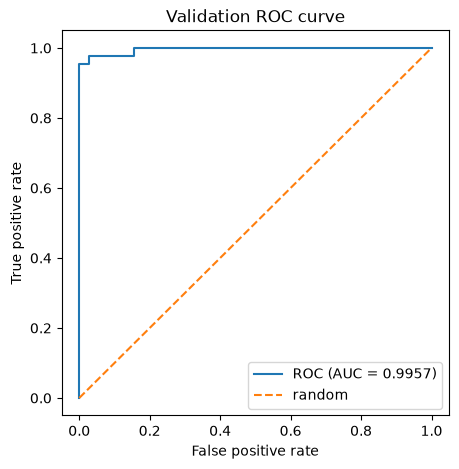

tau = 0.1460253243207389
[[66  6]
 [ 1 41]]
precision: 0.8723404255319149 recall: 0.9761904761904762


,threshold,precision,recall,FN,FP
0,0.500000,1.00000,0.952381,2,0
1,0.146025,0.87234,0.976190,1,6


In [371]:
w, h = train_gd(Xtr, y_tr_bc, 0.01, 0.5, 20000)
probability_validation = sigmoid(Xva @ w)
probability_test = sigmoid(Xte @ w)

prediction_test = predict(w, Xte)
cm = confusion_matrix(y_te_bc, prediction_test, 2)  # rows = actual, cols = predicted
precision, recall, f1, *_ = precision_recall_f1(cm) # *_ ignores the macro metrics, which we don't need here
print(cm)
print("precision:", precision[1], "recall:", recall[1], "F1:", f1[1])   # index 1 = malignant

def roc_curve(y, score):
    order = np.argsort(-score) # highest score first
    s, yy = score[order], y[order]
    tps = np.cumsum(yy)  # sums positives caught so far (true positives)
    fps = np.cumsum(1 - yy) # sums negatives wrongly flagged so far (false positives)
    idx = np.r_[np.where(np.diff(s))[0], len(s) - 1]   # only at distinct scores (handles ties)
    tpr = np.r_[0, tps[idx] / tps[-1]]
    fpr = np.r_[0, fps[idx] / fps[-1]]
    return fpr, tpr

fpr, tpr = roc_curve(y_va_bc, probability_validation)
auc = np.trapezoid(tpr, fpr)

from sklearn.metrics import roc_auc_score
print("my AUC:", auc, " sklearn:", roc_auc_score(y_va_bc, probability_validation))
assert abs(auc - roc_auc_score(y_va_bc, probability_validation)) < 1e-6

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", label="random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Validation ROC curve"); plt.legend(); plt.show()

# threshold τ for 100% recall (catch all positives)
tau = probability_validation[y_va_bc == 1].min()
print("tau =", tau)

pred_tau = (probability_test >= tau).astype(int) # τ is chosen on validation, then applied to test
cm_tau = confusion_matrix(y_te_bc, pred_tau, 2)
p2, r2, f2, *_ = precision_recall_f1(cm_tau)
print(cm_tau)
print("precision:", p2[1], "recall:", r2[1])

# comparison of metrics at threshold 0.5 and τ
display(pd.DataFrame({"threshold": [0.5, tau],
                      "precision": [precision[1], p2[1]],
                      "recall": [recall[1], r2[1]],
                      "FN": [cm[1, 0], cm_tau[1, 0]],
                      "FP": [cm[0, 1], cm_tau[0, 1]]}))

**Interpretation.** In a screening setting a false negative (a missed malignant tumor) is very costly because the patient goes untreated, while a false positive only leads to extra tests or a biopsy, which is costly but recoverable. Lowering the threshold from 0.5 to τ = 0.146 cut false negatives from 2 to 1 (recall 0.952 → 0.976) but raised false positives from 0 to 6 (precision 1.0 → 0.872), the usual recall–precision tradeoff. Because τ is set by the single least-confident positive among only 43 validation positives, it is a noisy estimate: it gave recall 1.0 on validation but still missed one malignant case on the test set. A more reliable τ would need cross-validation or more data.

## Task 16: The boundary in original coordinates

We train logistic regression ($\lambda=0$, $\eta=0.5$, 5000 epochs) on *mean radius* and *mean texture* only, standardized as $z_j = (x_j-\mu_j)/\sigma_j$. The score is

$$s = w_0 + \sum_j w_j\frac{x_j-\mu_j}{\sigma_j} = \Big(w_0 - \sum_j \frac{w_j\mu_j}{\sigma_j}\Big) + \sum_j \frac{w_j}{\sigma_j}\,x_j,$$

so in original coordinates $w_j^{orig} = w_j/\sigma_j$ and $w_0^{orig} = w_0 - \sum_j w_j\mu_j/\sigma_j$. The decision line is $s=0$.

max score difference: 3.552713678800501e-15


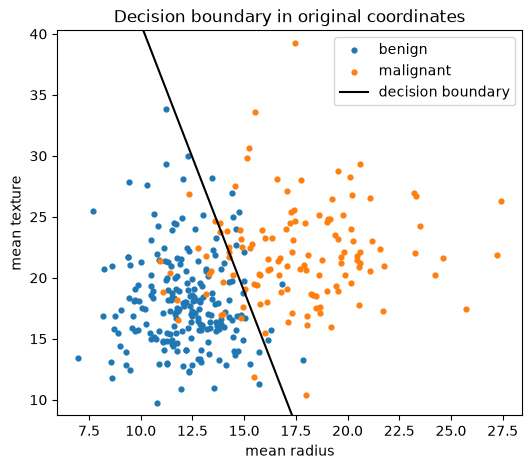

w (standardized): [-0.7272  3.6568  1.0099]  w (original): [-19.6434   1.0175   0.2319]
train accuracy: 0.9002932551319648  validation accuracy: 0.868421052631579


In [372]:
# 1. only two features, standardized with a new scaler fitted on these two columns
X2_tr = X_tr_bc[:, :2]
sc2 = Standardizer().fit(X2_tr)
X2_std = add_bias(sc2.transform(X2_tr))

w2, h = train_gd(X2_std, y_tr_bc, 0, 0.5, 5000)

# 2. convert weights to original coordinates
w_orig = np.zeros(3)
w_orig[1:] = w2[1:] / sc2.sigma
w_orig[0] = w2[0] - np.sum(w2[1:] * sc2.mu / sc2.sigma)

# 3. verify: scores must agree
X2_raw = add_bias(X2_tr)
diff = np.max(np.abs(X2_std @ w2 - X2_raw @ w_orig))
print("max score difference:", diff)
assert diff < 1e-9

# 4. plot the decision line over the raw data
plt.figure(figsize=(6, 5))
plt.scatter(X2_tr[y_tr_bc == 0, 0], X2_tr[y_tr_bc == 0, 1], s=12, label="benign")
plt.scatter(X2_tr[y_tr_bc == 1, 0], X2_tr[y_tr_bc == 1, 1], s=12, label="malignant")
x1 = np.linspace(X2_tr[:, 0].min(), X2_tr[:, 0].max(), 100)
x2 = -(w_orig[0] + w_orig[1] * x1) / w_orig[2]       # where score = 0
plt.plot(x1, x2, "k-", label="decision boundary")
plt.ylim(X2_tr[:, 1].min() - 1, X2_tr[:, 1].max() + 1)
plt.xlabel("mean radius"); plt.ylabel("mean texture")
plt.title("Decision boundary in original coordinates"); plt.legend(); plt.show()

Xva2 = add_bias(sc2.transform(X_va_bc[:, :2]))
print("w (standardized):", w2, " w (original):", w_orig)
print("train accuracy:", np.mean(predict(w2, X2_std) == y_tr_bc),
      " validation accuracy:", np.mean(predict(w2, Xva2) == y_va_bc))

**Interpretation.** The scores from the standardized weights and from the converted weights agree to about 4×10⁻¹⁵ (below 10⁻⁹), so they describe the same model. In original units the weights are w₀ = −19.64, 1.018 per unit of mean radius and 0.232 per unit of mean texture. Both are positive, so larger and rougher nuclei push the score toward malignant, and radius matters more per unit than texture. The line is the set where the score is 0 and it is drawn directly over the raw measurements. With only two features the classes overlap in the middle of the plot, so a single line cannot separate them: the accuracy is 0.900 on training and 0.868 on validation, well below the 30-feature model (about 0.985 and 0.974).

> AI-ASSISTED SECTION BEGINS (Part D, Tasks 17 to 22). Generated with Claude (Anthropic) and reviewed by the team member responsible for Part D.

# Part D: Softmax classifier

Symbols used below:

    N      number of images
    K      number of classes (10 digits)
    X      pixels with a column of ones added (bias column)
    W      weights, one column per digit
    S      scores = X @ W
    P      probabilities = softmax(S)
    Y      one-hot labels
    lam    regularization strength
    eta    learning rate

In [373]:
# Digits data: pixels / 16 (done in Task 1), plus a bias column, no standardization
X_train = add_bias(X_tr_dig)
X_val = add_bias(X_va_dig)
X_test = add_bias(X_te_dig)
y_train, y_val, y_test = y_tr_dig, y_va_dig, y_te_dig

num_classes = 10
num_train = X_train.shape[0]

## Task 17: Stable softmax and gradient

Step 1. Softmax turns the scores of one image into probabilities:

    P[i,k] = exp(S[i,k]) / ( exp(S[i,1]) + ... + exp(S[i,K]) )

Step 2. Loss of one image (c is the true class):

    loss_i = -log(P[i,c]) = -S[i,c] + log( sum over j of exp(S[i,j]) )

Step 3. Derivative of the loss with respect to one score:

    d loss_i / d S[i,k] = -1 (only if k = c) + exp(S[i,k]) / sum_j exp(S[i,j])
                        = P[i,k] - Y[i,k]

Step 4. S[i,k] = sum over m of X[i,m] * W[m,k], so the derivative of S[i,k] with respect to W[m,k] is X[i,m]. Averaging over the N images gives (1/N) * X^T (P - Y).

Step 5. The penalty (lam/2) * sum of W[1:]^2 has derivative lam * W for every row except the bias row (row 0), which is not penalized. So:

    dL/dW = (1/N) * X^T (P - Y) + lam * [0 ; W[1:]]

One-line proof that softmax(s + c) = softmax(s):

    exp(s_k + c) / sum_j exp(s_j + c) = exp(c) * exp(s_k) / ( exp(c) * sum_j exp(s_j) ) = softmax(s)_k

So we subtract max(s) from the scores first. This keeps exp() from overflowing.

In [374]:
def softmax(S):
    S = S - S.max(axis=1, keepdims=True)      # subtract the row maximum
    E = np.exp(S)
    return E / E.sum(axis=1, keepdims=True)   # each row now sums to 1


def log_sum_exp(S):
    m = S.max(axis=1, keepdims=True)
    return (m + np.log(np.exp(S - m).sum(axis=1, keepdims=True))).ravel()


def data_loss(W, X, y):
    # mean cross-entropy, without the penalty
    S = np.dot(X, W)
    correct_scores = S[np.arange(len(y)), y]  # score of the true class of each image
    return np.mean(log_sum_exp(S) - correct_scores)


def total_loss(W, X, y, lam):
    # data loss plus the penalty (the bias row W[0] is not penalized)
    return data_loss(W, X, y) + 0.5 * lam * np.sum(W[1:] ** 2)


def gradient(W, X, y, lam):
    N = len(y)
    P = softmax(np.dot(X, W))
    P[np.arange(N), y] -= 1                   # P becomes P - Y
    G = np.dot(X.T, P) / N
    G[1:] += lam * W[1:]                      # penalty gradient, not for the bias row
    return G


def predict(W, X):
    return np.argmax(np.dot(X, W), axis=1)    # class with the highest score

In [375]:
# Example from the assignment: [1000, 1001, 1002]
scores = np.array([[1000.0, 1001.0, 1002.0]])
with np.errstate(all="ignore"):
    naive = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)
print("naive softmax :", naive)
print("stable softmax:", softmax(scores))

# Loss at W = 0 should be ln(10)
W_zero = np.zeros((X_train.shape[1], num_classes))
print("loss at W = 0 :", data_loss(W_zero, X_train, y_train))
print("ln(10)        :", np.log(10))

# Gradient check on 100 random entries of W, with lam = 0.1
rng = np.random.default_rng(SEED)
W_random = rng.normal(0, 0.1, size=W_zero.shape)
error = grad_check(lambda W: total_loss(W, X_train, y_train, 0.1),
                   lambda W: gradient(W, X_train, y_train, 0.1),
                   W_random)
print("gradient check relative error:", error)
assert error < 1e-6

naive softmax : [[nan nan nan]]
stable softmax: [[0.09   0.2447 0.6652]]
loss at W = 0 : 2.3025850929940463
ln(10)        : 2.302585092994046
gradient check relative error: 8.106289964534921e-10


**Interpretation.** The naive softmax overflows to nan, while the stable version gives [0.0900, 0.2447, 0.6652]. At W = 0 all scores are 0, so every class gets probability 1/10 and the loss is ln(10) for any labels. The gradient check error is about 8e-10, which is below 1e-6, so the gradient is correct.

## Task 18: Training and model selection

Mini-batch gradient descent with batch size 64 and 100 epochs. W starts at 0. The images are shuffled every epoch and the last smaller batch is kept. Each update is:

    W = W - eta * gradient(W, batch)

In [376]:
def train(X, y, lam, eta, epochs, batch_size, rng, X_val=None, y_val=None):
    N = X.shape[0]
    W = np.zeros((X.shape[1], int(y.max()) + 1))
    num_batches = int(np.ceil(N / batch_size))   # the last batch may be smaller
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        order = rng.permutation(N)               # new shuffle every epoch
        for b in range(num_batches):
            idx = order[b * batch_size:(b + 1) * batch_size]
            W = W - eta * gradient(W, X[idx], y[idx], lam)

        # record loss and accuracy after each epoch (loss without the penalty)
        history["train_loss"].append(data_loss(W, X, y))
        history["train_acc"].append(accuracy(y, predict(W, X)))
        if X_val is not None:
            history["val_loss"].append(data_loss(W, X_val, y_val))
            history["val_acc"].append(accuracy(y_val, predict(W, X_val)))
    return W, history

,eta,train loss,val loss,train acc,val acc
0,0.01,0.808641,0.837388,0.924791,0.911111
1,0.10,0.203817,0.238951,0.960074,0.950000
2,0.50,0.086785,0.138329,0.988858,0.961111
3,1.00,0.056569,0.119327,0.996286,0.961111


best eta = 1.0


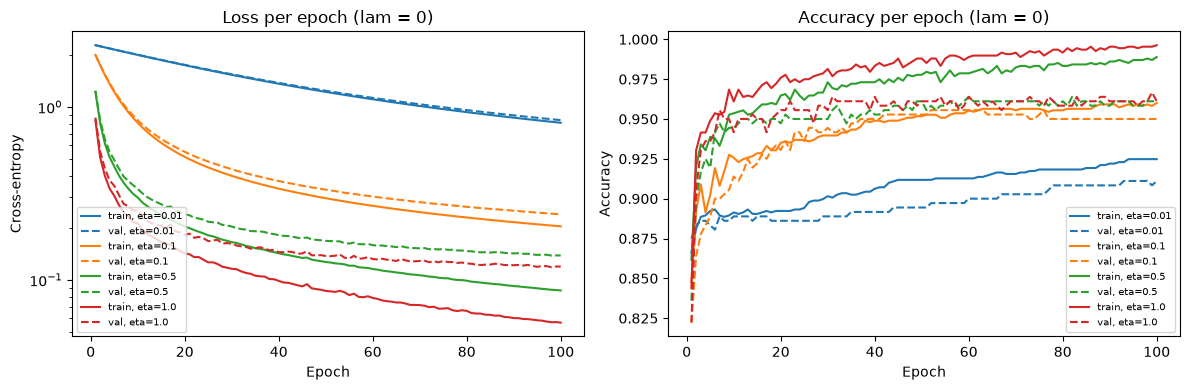

In [377]:
# (a) different learning rates, lam = 0
etas = [0.01, 0.1, 0.5, 1.0]
histories = {}
rows = []
for eta in etas:
    rng = np.random.default_rng(SEED)
    W, h = train(X_train, y_train, 0.0, eta, 100, 64, rng, X_val, y_val)
    histories[eta] = h
    rows.append({"eta": eta,
                 "train loss": h["train_loss"][-1], "val loss": h["val_loss"][-1],
                 "train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1]})

eta_table = pd.DataFrame(rows)
display(eta_table)

# choose eta with the lowest final validation loss
best_eta = eta_table.loc[eta_table["val loss"].idxmin(), "eta"]
print("best eta =", best_eta)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, eta in enumerate(etas):
    h = histories[eta]
    ax[0].plot(range(1, 101), h["train_loss"], "C" + str(k), label="train, eta=" + str(eta))
    ax[0].plot(range(1, 101), h["val_loss"], "C" + str(k) + "--", label="val, eta=" + str(eta))
    ax[1].plot(range(1, 101), h["train_acc"], "C" + str(k), label="train, eta=" + str(eta))
    ax[1].plot(range(1, 101), h["val_acc"], "C" + str(k) + "--", label="val, eta=" + str(eta))
ax[0].set_title("Loss per epoch (lam = 0)")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Cross-entropy")
ax[0].set_yscale("log")
ax[0].legend(fontsize=7)
ax[1].set_title("Accuracy per epoch (lam = 0)")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation (a).** eta = 0.01 is under-trained after 100 epochs (validation loss 0.837). Larger learning rates reach a lower loss, and the lowest final validation loss is at eta = 1.0 (0.119), so best eta = 1.0.

In [378]:
# (b) different lam values, using the best eta
lams = [0, 1e-4, 1e-3, 1e-2, 1e-1]
weights = {}
rows = []
for lam in lams:
    rng = np.random.default_rng(SEED)
    W, h = train(X_train, y_train, lam, best_eta, 100, 64, rng, X_val, y_val)
    weights[lam] = W
    rows.append({"lam": lam,
                 "train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1],
                 "val loss": h["val_loss"][-1], "norm of W[1:]": np.linalg.norm(W[1:])})

lam_table = pd.DataFrame(rows)
display(lam_table)

# choose lam with the best validation accuracy; if tied, take the larger lam
best_val_acc = lam_table["val acc"].max()
best_lam = lam_table.loc[lam_table["val acc"] == best_val_acc, "lam"].max()
W_best = weights[best_lam]
print("best lam =", best_lam)

# test accuracy, reported once
print("test accuracy:", accuracy(y_test, predict(W_best, X_test)))

,lam,train acc,val acc,val loss,norm of W[1:]
0,0.0000,0.996286,0.961111,0.119327,24.844136
1,0.0001,0.996286,0.963889,0.124232,23.063295
2,0.0010,0.980501,0.966667,0.182245,15.617225
3,0.0100,0.938719,0.927778,0.464233,8.016528
4,0.1000,0.641597,0.633333,1.383951,2.896881


best lam = 0.001
test accuracy: 0.9527777777777777


**Interpretation (b).** lam = 0.001 has the best validation accuracy (0.9667, inside the expected range 0.95 to 0.98). lam = 0.1 is far too strong (validation accuracy 0.633). The test accuracy for lam = 0.001 is 0.9528.

## Task 19: Comparison with scikit-learn

scikit-learn minimizes C * (sum of losses) + 0.5 * (norm of W)^2. Dividing by C * N gives our objective with lam = 1 / (C * N). So:

    C = 1 / (lam * N_train)

For lam = 0 we use penalty=None.

In [379]:
from sklearn.linear_model import LogisticRegression


def fit_sklearn(lam=None, C=None):
    if lam is not None:
        if lam == 0:
            model = LogisticRegression(penalty=None, max_iter=10000)
        else:
            model = LogisticRegression(C=1.0 / (lam * num_train), max_iter=10000)
    else:
        model = LogisticRegression(C=C, max_iter=10000)
    model.fit(X_tr_dig, y_train)     # no bias column: scikit-learn adds its own intercept
    return model


# same lam values as Task 18
sk_models = {}
rows = []
for lam in lams:
    model = fit_sklearn(lam=lam)
    sk_models[lam] = model
    W = weights[lam]
    rows.append({"lam": lam,
                 "C": np.inf if lam == 0 else 1.0 / (lam * num_train),
                 "own val": accuracy(y_val, predict(W, X_val)),
                 "sklearn val": accuracy(y_val, model.predict(X_va_dig)),
                 "own test": accuracy(y_test, predict(W, X_test)),
                 "sklearn test": accuracy(y_test, model.predict(X_te_dig))})
display(pd.DataFrame(rows))

# how often the test predictions agree at the best lam
same = np.mean(predict(W_best, X_test) == sk_models[best_lam].predict(X_te_dig))
print("test predictions agree at best lam:", same)
assert same >= 0.97

# sweep over C; our model uses lam = 1 / (C * N)
rows = []
for C in [0.1, 1, 10, 100]:
    lam = 1.0 / (C * num_train)
    rng = np.random.default_rng(SEED)
    W, _ = train(X_train, y_train, lam, best_eta, 100, 64, rng)
    model = fit_sklearn(C=C)
    rows.append({"C": C,
                 "own val": accuracy(y_val, predict(W, X_val)),
                 "sklearn val": accuracy(y_val, model.predict(X_va_dig)),
                 "own test": accuracy(y_test, predict(W, X_test)),
                 "sklearn test": accuracy(y_test, model.predict(X_te_dig))})
display(pd.DataFrame(rows))

,lam,C,own val,sklearn val,own test,sklearn test
0,0.0000,inf,0.961111,0.955556,0.958333,0.955556
1,0.0001,9.285051,0.963889,0.975000,0.958333,0.961111
2,0.0010,0.928505,0.966667,0.972222,0.952778,0.955556
3,0.0100,0.092851,0.927778,0.947222,0.925000,0.933333
4,0.1000,0.009285,0.633333,0.902778,0.619444,0.886111


test predictions agree at best lam: 0.9916666666666667


,C,own val,sklearn val,own test,sklearn test
0,0.1,0.927778,0.950000,0.925000,0.938889
1,1.0,0.966667,0.972222,0.952778,0.955556
2,10.0,0.963889,0.963889,0.958333,0.955556
3,100.0,0.961111,0.961111,0.958333,0.955556


**Interpretation.** At the best lam our test predictions agree with scikit-learn on 99.2% of the images, and for C = 10 and C = 100 both models have the same validation accuracy. They differ more when the regularization is strong (for example lam = 0.1), because 100 mini-batch epochs are not enough to converge on that problem, while scikit-learn's solver runs until it converges.

## Task 20: Error analysis

All results use the best model on the test set. In the confusion matrix, rows are the true digit and columns are the predicted digit.

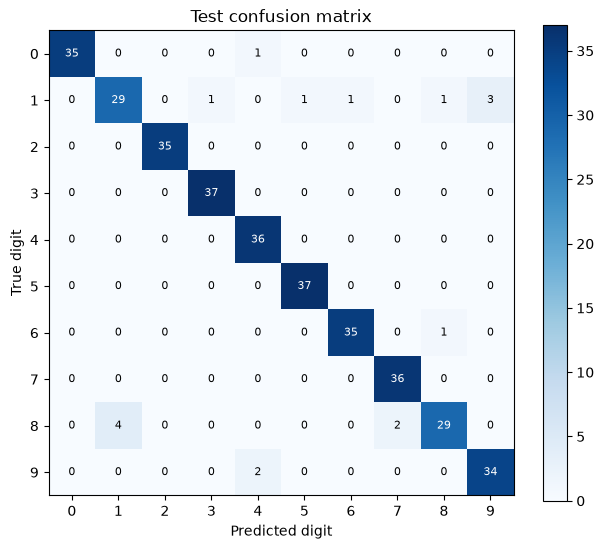

,digit,precision,recall,F1
0,0,1.000000,0.972222,0.985915
1,1,0.878788,0.805556,0.840580
2,2,1.000000,1.000000,1.000000
3,3,0.973684,1.000000,0.986667
4,4,0.923077,1.000000,0.960000
5,5,0.973684,1.000000,0.986667
6,6,0.972222,0.972222,0.972222
7,7,0.947368,1.000000,0.972973
8,8,0.935484,0.828571,0.878788
9,9,0.918919,0.944444,0.931507


Three most confused pairs (true -> predicted : count)
8 -> 1 : 4
1 -> 9 : 3
8 -> 7 : 2


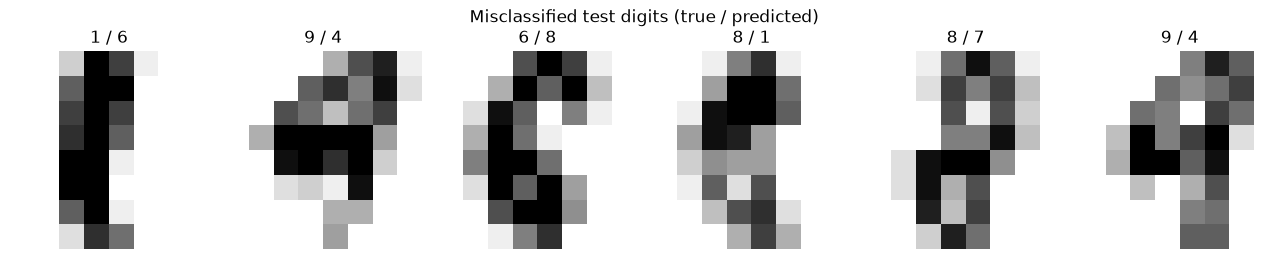

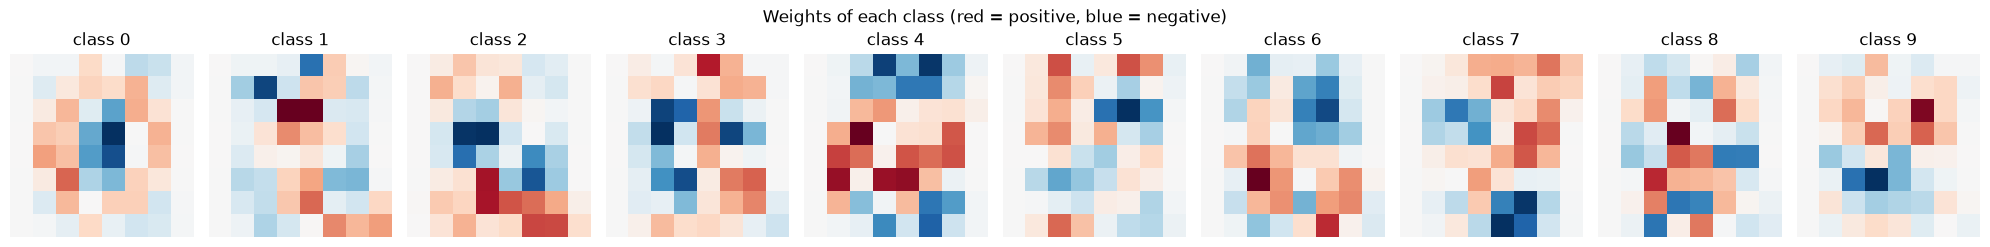

In [380]:
test_pred = predict(W_best, X_test)
cm = confusion_matrix(y_test, test_pred, num_classes)

# confusion matrix as a heat map
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(cm, cmap="Blues")
for i in range(num_classes):
    for j in range(num_classes):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color, fontsize=8)
ax.set_xticks(range(num_classes))
ax.set_yticks(range(num_classes))
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
ax.set_title("Test confusion matrix")
plt.colorbar(image)
plt.tight_layout()
plt.show()

# precision, recall and F1 for each digit
precision, recall, f1, _, _, _ = precision_recall_f1(cm)
display(pd.DataFrame({"digit": range(num_classes), "precision": precision, "recall": recall, "F1": f1}))

# three most confused pairs: remove the diagonal, then take the largest entries
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)
print("Three most confused pairs (true -> predicted : count)")
for flat_index in np.argsort(mistakes, axis=None)[::-1][:3]:
    true_digit, pred_digit = np.unravel_index(flat_index, mistakes.shape)
    print(true_digit, "->", pred_digit, ":", mistakes[true_digit, pred_digit])

# six misclassified test digits
wrong = np.where(test_pred != y_test)[0][:6]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for ax, i in zip(axes, wrong):
    ax.imshow(X_te_dig[i].reshape(8, 8), cmap="gray_r")
    ax.axis("off")
    ax.set_title(str(y_test[i]) + " / " + str(test_pred[i]))
plt.suptitle("Misclassified test digits (true / predicted)")
plt.tight_layout()
plt.show()

# weights of each class as an 8x8 image (bias excluded)
fig, axes = plt.subplots(1, num_classes, figsize=(20, 2.5))
for k, ax in enumerate(axes):
    weight_image = W_best[1:, k].reshape(8, 8)
    limit = np.abs(weight_image).max()
    ax.imshow(weight_image, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.axis("off")
    ax.set_title("class " + str(k))
plt.suptitle("Weights of each class (red = positive, blue = negative)")
plt.tight_layout()
plt.show()

**Interpretation.** The hardest digits are 1 (recall 0.81) and 8 (recall 0.83), and the most confused pairs are 8 to 1, 1 to 9 and 8 to 7. A linear model on raw pixels keeps one fixed template per digit, so it works only when the strokes fall on the same pixels as the template. The digit 8 shares strokes with 1, 7 and 9, and a 1 can be written at very different slants and thicknesses, so one template cannot cover them. Digits with a distinctive layout, such as 2, 3 and 5, are classified almost perfectly.

## Task 21: Softmax with 2 classes is logistic regression

Let s0 = w0 . x and s1 = w1 . x be the two scores. Then:

    P(y=1 | x) = exp(s1) / ( exp(s0) + exp(s1) )
               = 1 / ( 1 + exp(-(s1 - s0)) )          (divide top and bottom by exp(s1))
               = sigmoid( (w1 - w0) . x )

In [381]:
# standardized breast cancer test features (training mean and std), plus bias column
scaler = Standardizer().fit(X_tr_bc)
X_bc_test = add_bias(scaler.transform(X_te_bc))       # 31 columns

# random 31 x 2 weight matrix
rng = np.random.default_rng(SEED)
W_two = rng.normal(size=(X_bc_test.shape[1], 2))

prob_softmax = softmax(np.dot(X_bc_test, W_two))[:, 1]
prob_sigmoid = sigmoid(np.dot(X_bc_test, W_two[:, 1] - W_two[:, 0]))

biggest_difference = np.max(np.abs(prob_softmax - prob_sigmoid))
print("biggest difference:", biggest_difference)
assert biggest_difference < 1e-12

biggest difference: 6.661338147750939e-16


**Interpretation.** The two probabilities differ by about 4e-16, which is only rounding error. So a softmax with 2 classes is logistic regression with the weight vector w1 - w0.

## Task 22: Seeing the boundaries (Iris)

We use petal length and petal width, standardized with the training mean and std. Our softmax is trained with full batch (batch size = N), eta = 0.5 and 2000 epochs, for lam = 0 and lam = 1. We compare with scikit-learn using C = 1 / (lam * N_train).

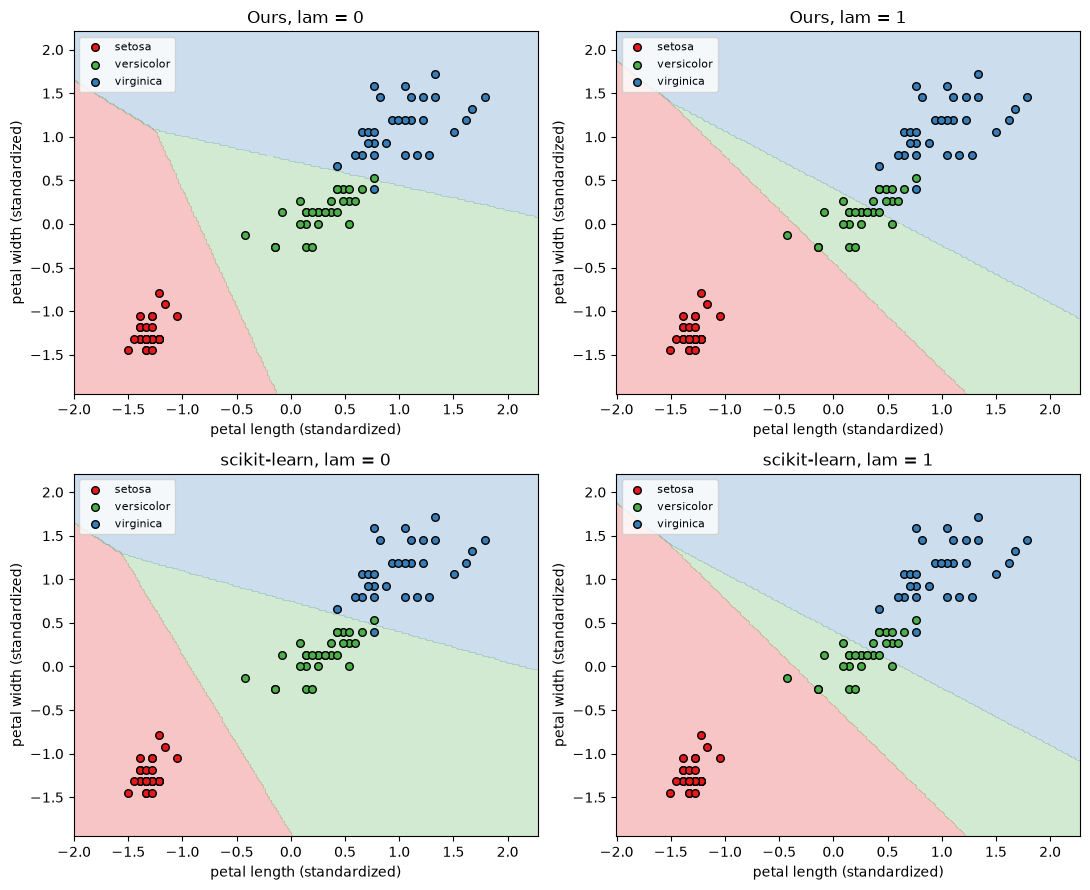

In [382]:
# features 2 and 3 of Iris: petal length and petal width
iris_scaler = Standardizer().fit(X_tr_iris[:, [2, 3]])
iris_train = iris_scaler.transform(X_tr_iris[:, [2, 3]])
iris_train_bias = add_bias(iris_train)
iris_labels = y_tr_iris
num_iris = len(iris_labels)


def plot_decision_regions(predict_function, X, y, ax, title, class_names):
    # grid of points covering the plot area
    x_values = np.arange(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 0.02)
    y_values = np.arange(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 0.02)
    xx, yy = np.meshgrid(x_values, y_values)
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    # predicted class at every grid point
    Z = predict_function(grid_points).reshape(xx.shape)

    colors = ["#e41a1c", "#4daf4a", "#377eb8"]
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.25)
    for k in range(3):
        ax.scatter(X[y == k, 0], X[y == k, 1], c=colors[k], edgecolor="k", s=30, label=class_names[k])
    ax.set_xlabel("petal length (standardized)")
    ax.set_ylabel("petal width (standardized)")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for col, lam in enumerate([0, 1]):
    # our model, full batch
    rng = np.random.default_rng(SEED)
    W_iris, _ = train(iris_train_bias, iris_labels, lam, 0.5, 2000, num_iris, rng)
    plot_decision_regions(lambda points: predict(W_iris, add_bias(points)),
                          iris_train, iris_labels, axes[0, col],
                          "Ours, lam = " + str(lam), iris.target_names)

    # scikit-learn with the matching C
    if lam == 0:
        model = LogisticRegression(penalty=None, max_iter=10000)
    else:
        model = LogisticRegression(C=1.0 / (lam * num_iris), max_iter=10000)
    model.fit(iris_train, iris_labels)
    plot_decision_regions(model.predict, iris_train, iris_labels, axes[1, col],
                          "scikit-learn, lam = " + str(lam), iris.target_names)
plt.tight_layout()
plt.show()

**Interpretation.** Softmax gives three straight-line regions that meet at one point. Setosa is clearly separated, while versicolor and virginica overlap, so the boundary between them is where the errors are. With lam = 1 the boundaries move away from the best-fitting positions and several versicolor points near them are misclassified. Our regions are almost identical to scikit-learn's at lam = 1 and very close at lam = 0.

> AI-ASSISTED SECTION ENDS (Part D).